# 🏭 Manufacturing Equipment Output Prediction
## Linear Regression Model Development

**Project:** Data Science Capstone Project  
**Target:** `Parts_Per_Hour`  
**Dataset:** `manufacturing_dataset_1000_samples.csv`

This notebook combines the useful modeling and preprocessing work from the two team notebooks into one clean, small-cell workflow.

### Workflow
1. Load and understand the dataset
2. Perform essential EDA
3. Engineer useful timestamp features
4. Split the data
5. Build preprocessing pipelines
6. Train a baseline Linear Regression model
7. Evaluate the baseline model
8. Analyze multicollinearity
9. Build the refined Linear Regression model
10. Compare baseline vs refined model
11. Run final diagnostics
12. Save the final model for Streamlit deployment

## 1. Import Libraries

In [4]:
!pip install joblib


!{sys.executable} -m pip install pandas numpy matplotlib seaborn scikit-learn scipy statsmodels joblib
import os
import sys
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from statsmodels.stats.outliers_influence import variance_inflation_factor

print("Libraries imported successfully.")

Defaulting to user installation because normal site-packages is not writeable


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


     ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
     ---------------------------------------- 0.1/11.3 MB 2.3 MB/s eta 0:00:05
      --------------------------------------- 0.2/11.3 MB 2.5 MB/s eta 0:00:05
      --------------------------------------- 0.2/11.3 MB 2.5 MB/s eta 0:00:05
     - -------------------------------------- 0.4/11.3 MB 2.6 MB/s eta 0:00:05
     - -------------------------------------- 0.4/11.3 MB 2.1 MB/s eta 0:00:06
     - -------------------------------------- 0.4/11.3 MB 1.8 MB/s eta 0:00:07
     - -------------------------------------- 0.4/11.3 MB 1.8 MB/s eta 0:00:07
     - -------------------------------------- 0.5/11.3 MB 1.3 MB/s eta 0:00:09
     -- ------------------------------------- 0.6/11.3 MB 1.5 MB/s eta 0:00:07
     -- ------------------------------------- 0.7/11.3 MB 1.7 MB/s eta 0:00:07
     -- ------------------------------------- 0.8/11.3 MB 1.6 MB/s eta 0:00:07
     -- ------------------------------------- 0.8/11.3 MB 1

## 2. Load the Dataset

In [6]:
DATA_PATH = r"D:\manufacturing_dataset_1000_samples.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (1000, 19)


In [7]:
print("Dataset shape:", df.shape)

Dataset shape: (1000, 19)


In [8]:
df.head()

,Timestamp,Injection_Temperature,Injection_Pressure,Cycle_Time,Cooling_Time,Material_Viscosity,Ambient_Temperature,Machine_Age,Operator_Experience,Maintenance_Hours,Shift,Machine_Type,Material_Grade,Day_of_Week,Temperature_Pressure_Ratio,Total_Cycle_Time,Efficiency_Score,Machine_Utilization,Parts_Per_Hour
0,01-01-2023 00:00,221.0,136.0,28.7,13.6,375.5,28.0,3.8,11.2,64,Evening,Type_B,Economy,Thursday,1.625,42.3,0.063,0.510,36.5
1,01-01-2023 01:00,213.3,128.9,34.5,14.0,215.8,22.6,6.8,6.3,58,Night,Type_A,Standard,Wednesday,1.655,48.5,0.037,0.389,29.9
2,01-01-2023 02:00,222.8,115.9,19.9,9.5,307.0,25.3,4.2,9.6,47,Day,Type_A,Standard,Monday,1.922,29.4,0.061,0.551,56.9
3,01-01-2023 03:00,233.3,105.3,39.2,13.1,137.8,26.0,9.2,8.6,49,Evening,Type_A,Premium,Saturday,2.215,52.3,0.054,0.293,31.0
4,01-01-2023 04:00,212.2,125.5,45.0,9.9,298.2,23.6,6.2,23.0,49,Night,Type_B,Premium,Monday,1.691,54.9,0.145,0.443,15.0


## 3. Basic Dataset Understanding

In [10]:
print("Column names:")
for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

Column names:
1. Timestamp
2. Injection_Temperature
3. Injection_Pressure
4. Cycle_Time
5. Cooling_Time
6. Material_Viscosity
7. Ambient_Temperature
8. Machine_Age
9. Operator_Experience
10. Maintenance_Hours
11. Shift
12. Machine_Type
13. Material_Grade
14. Day_of_Week
15. Temperature_Pressure_Ratio
16. Total_Cycle_Time
17. Efficiency_Score
18. Machine_Utilization
19. Parts_Per_Hour


In [9]:
print("Data types:")
display(df.dtypes.to_frame(name="Data Type"))

Data types:


,Data Type
Timestamp,object
Injection_Temperature,float64
Injection_Pressure,float64
Cycle_Time,float64
Cooling_Time,float64
Material_Viscosity,float64
Ambient_Temperature,float64
Machine_Age,float64
Operator_Experience,float64
Maintenance_Hours,int64


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Timestamp                   1000 non-null   object 
 1   Injection_Temperature       1000 non-null   float64
 2   Injection_Pressure          1000 non-null   float64
 3   Cycle_Time                  1000 non-null   float64
 4   Cooling_Time                1000 non-null   float64
 5   Material_Viscosity          980 non-null    float64
 6   Ambient_Temperature         980 non-null    float64
 7   Machine_Age                 1000 non-null   float64
 8   Operator_Experience         980 non-null    float64
 9   Maintenance_Hours           1000 non-null   int64  
 10  Shift                       1000 non-null   object 
 11  Machine_Type                1000 non-null   object 
 12  Material_Grade              1000 non-null   object 
 13  Day_of_Week                 1000 n

In [12]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Injection_Temperature,1000.0,215.315900,11.995507,180.000,207.20000,215.3000,222.80000,300.000
Injection_Pressure,1000.0,116.075000,14.667246,80.000,105.90000,115.9500,125.92500,150.000
Cycle_Time,1000.0,35.851700,8.353490,16.300,28.80000,36.8500,45.00000,60.000
Cooling_Time,1000.0,11.923200,2.304290,8.000,10.27500,11.9000,13.50000,19.900
Material_Viscosity,980.0,251.630714,73.348695,104.600,200.90000,242.7000,295.30000,1000.000
Ambient_Temperature,980.0,22.941224,2.773712,18.000,20.80000,22.9000,25.10000,28.000
Machine_Age,1000.0,7.855900,3.900798,1.000,4.70000,7.9000,11.10000,15.000
Operator_Experience,980.0,30.795204,27.684769,1.000,9.80000,22.1000,43.42500,120.000
Maintenance_Hours,1000.0,50.580000,16.014558,26.000,45.00000,50.0000,55.00000,500.000
Temperature_Pressure_Ratio,1000.0,1.885852,0.274323,1.286,1.68375,1.8495,2.04425,2.843


## 4. Data Quality Checks

In [13]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Material_Viscosity     20
Ambient_Temperature    20
Operator_Experience    20
dtype: int64

In [14]:
missing_table = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

display(missing_table[missing_table["Missing Values"] > 0])

,Missing Values,Missing Percentage
Material_Viscosity,20,2.0
Ambient_Temperature,20,2.0
Operator_Experience,20,2.0


In [15]:
duplicate_count = df.duplicated().sum()
print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


## 5. Target Variable Analysis

In [16]:
TARGET = "Parts_Per_Hour"

print("Target variable:", TARGET)
print("Target range:", df[TARGET].min(), "to", df[TARGET].max())
print("Target mean:", round(df[TARGET].mean(), 2))
print("Target median:", round(df[TARGET].median(), 2))

Target variable: Parts_Per_Hour
Target range: 5.0 to 68.6
Target mean: 29.3
Target median: 28.2


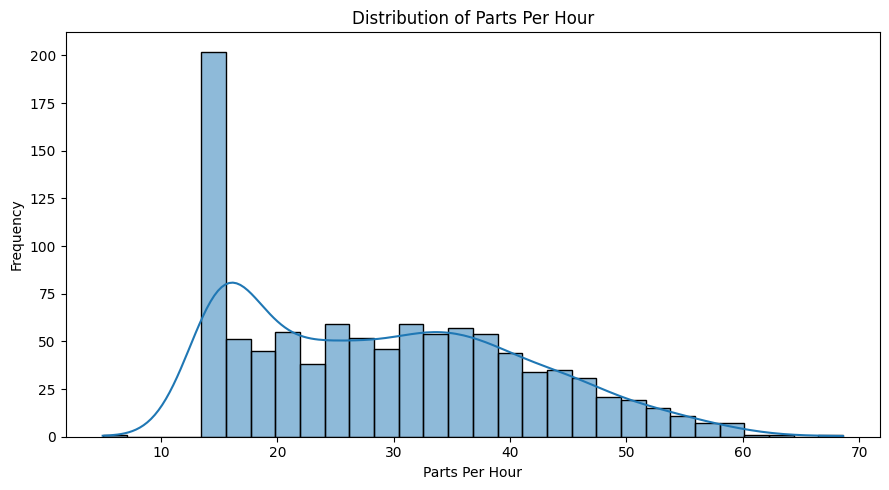

In [17]:
plt.figure(figsize=(9, 5))

sns.histplot(
    df[TARGET],
    bins=30,
    kde=True
)

plt.title("Distribution of Parts Per Hour")
plt.xlabel("Parts Per Hour")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## 6. Numerical Feature Exploration

In [18]:
numerical_features = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

Numerical features:
['Injection_Temperature', 'Injection_Pressure', 'Cycle_Time', 'Cooling_Time', 'Material_Viscosity', 'Ambient_Temperature', 'Machine_Age', 'Operator_Experience', 'Maintenance_Hours', 'Temperature_Pressure_Ratio', 'Total_Cycle_Time', 'Efficiency_Score', 'Machine_Utilization', 'Parts_Per_Hour']


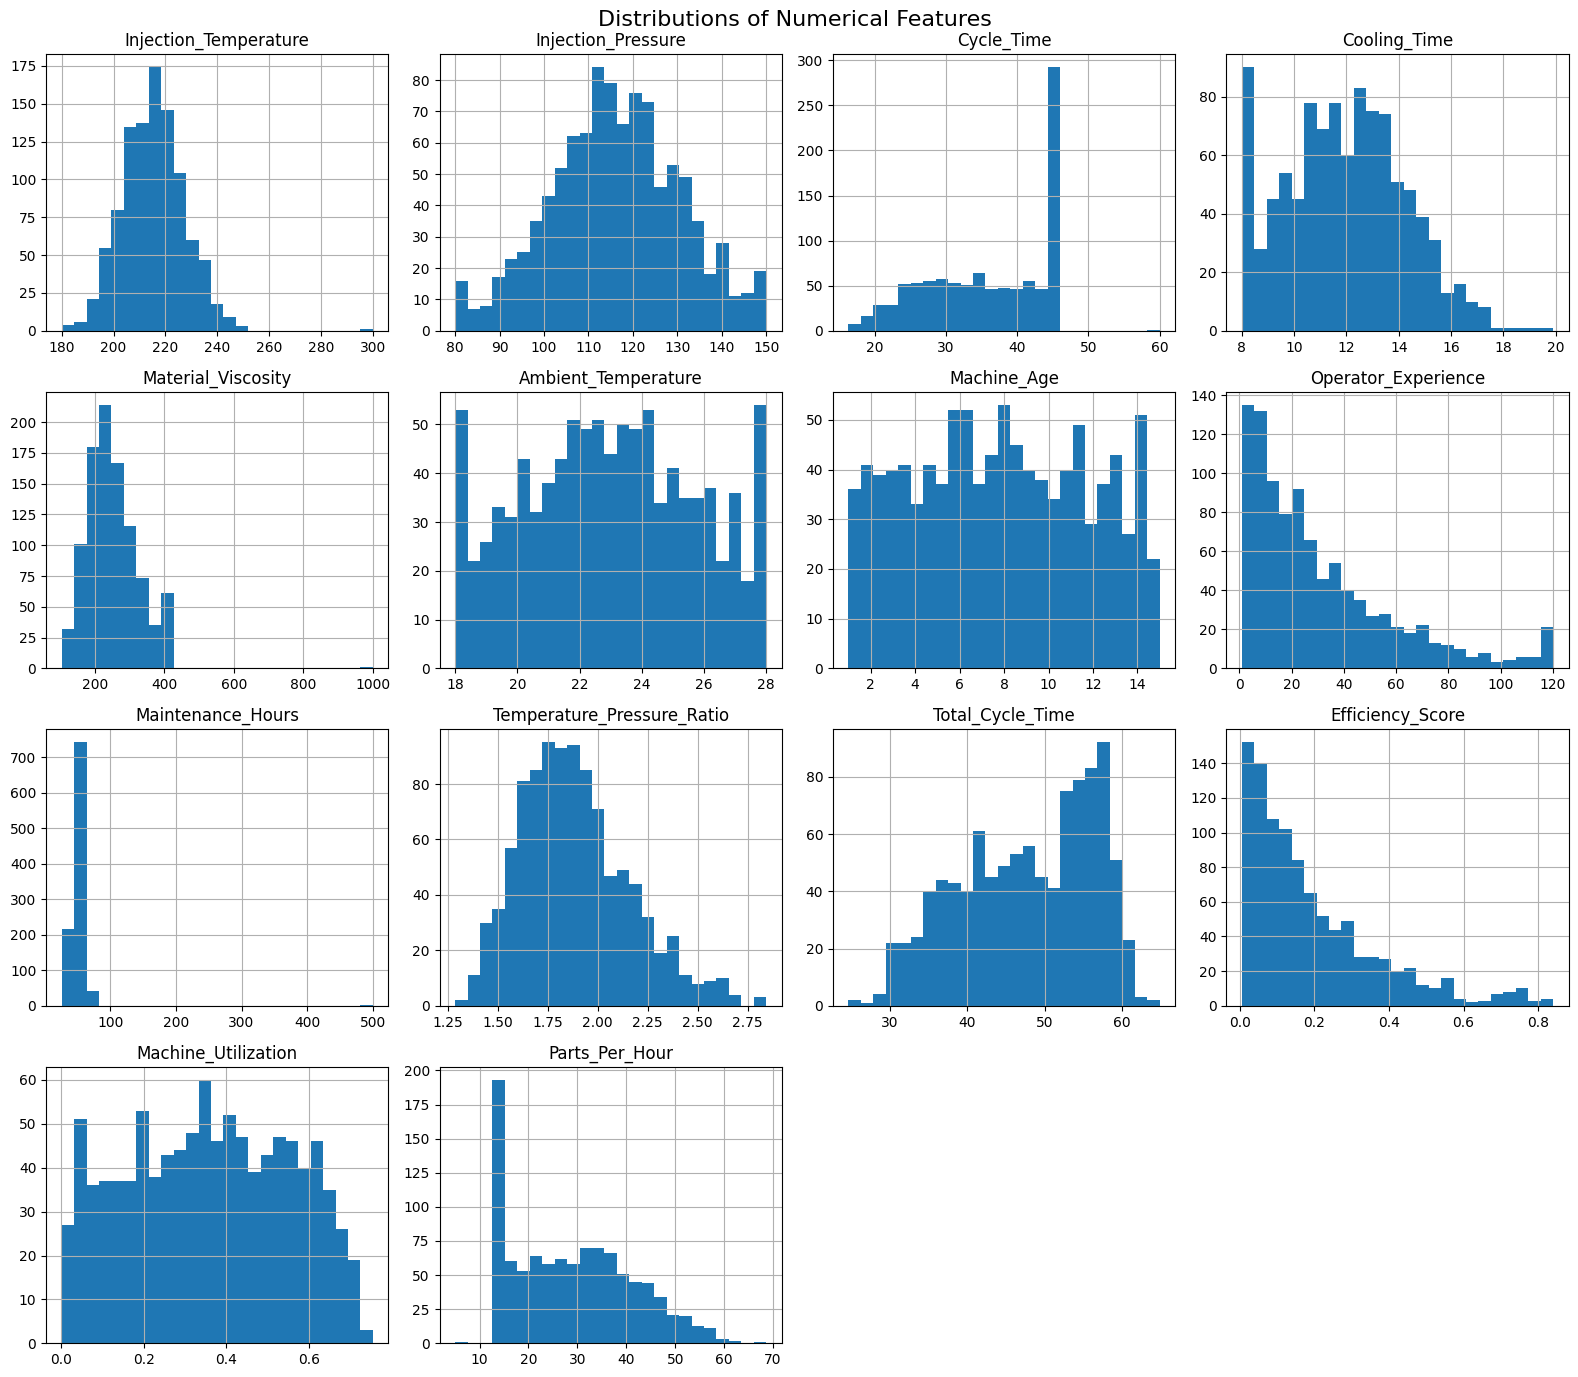

In [19]:
df[numerical_features].hist(
    figsize=(16, 14),
    bins=25
)

plt.suptitle(
    "Distributions of Numerical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

## 7. Categorical Feature Exploration

In [20]:
categorical_features = [
    "Shift",
    "Machine_Type",
    "Material_Grade",
    "Day_of_Week"
]

print("Categorical features:")
print(categorical_features)

Categorical features:
['Shift', 'Machine_Type', 'Material_Grade', 'Day_of_Week']


In [21]:
for column in categorical_features:
    print(f"\n{column}:")
    print(df[column].value_counts())


Shift:
Shift
Day        517
Evening    277
Night      206
Name: count, dtype: int64

Machine_Type:
Machine_Type
Type_A    384
Type_B    347
Type_C    269
Name: count, dtype: int64

Material_Grade:
Material_Grade
Standard    591
Premium     210
Economy     199
Name: count, dtype: int64

Day_of_Week:
Day_of_Week
Friday       168
Wednesday    155
Thursday     150
Saturday     141
Tuesday      138
Monday       136
Sunday       112
Name: count, dtype: int64


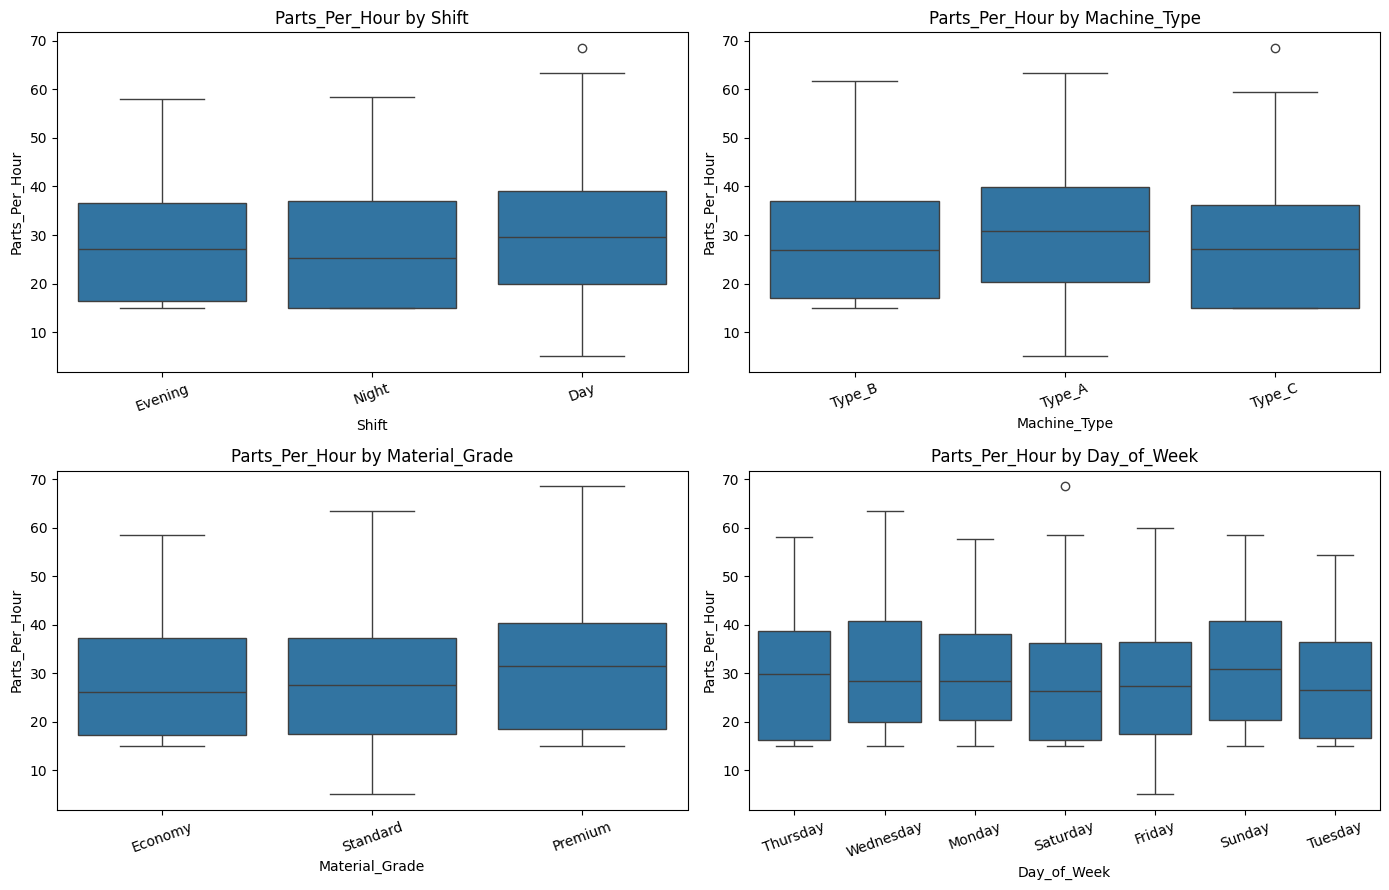

In [22]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 9)
)

for ax, column in zip(axes.ravel(), categorical_features):
    sns.boxplot(
        data=df,
        x=column,
        y=TARGET,
        ax=ax
    )
    ax.set_title(f"{TARGET} by {column}")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

## 8. Correlation Analysis

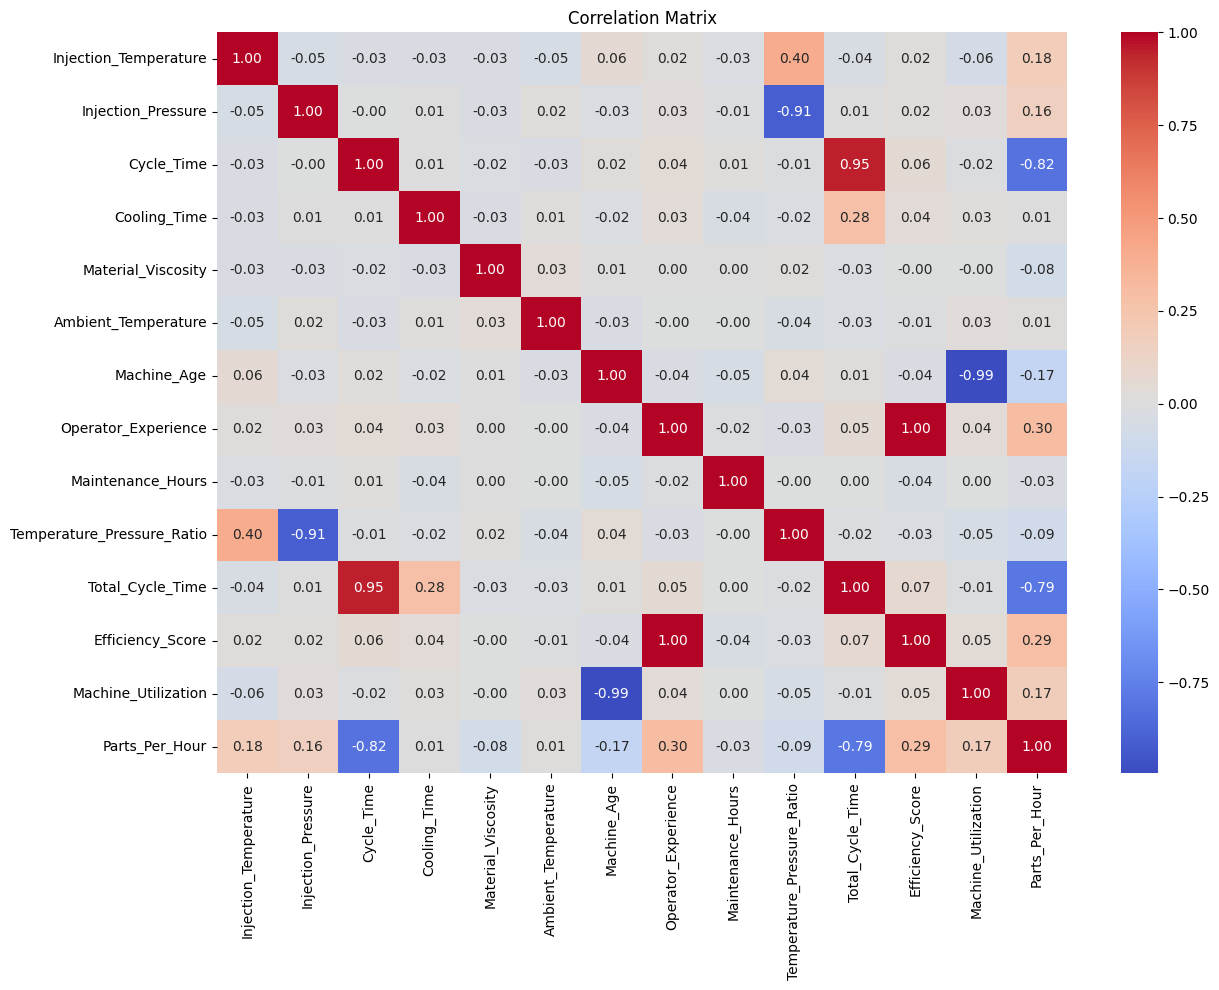

In [23]:
correlation_matrix = df.select_dtypes(
    include=["int64", "float64"]
).corr()

plt.figure(figsize=(13, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [24]:
target_correlations = (
    correlation_matrix[TARGET]
    .drop(TARGET)
    .sort_values(key=np.abs, ascending=False)
)

display(
    target_correlations.to_frame(
        name="Correlation with Parts_Per_Hour"
    )
)

,Correlation with Parts_Per_Hour
Cycle_Time,-0.819446
Total_Cycle_Time,-0.792862
Operator_Experience,0.300891
Efficiency_Score,0.286794
Injection_Temperature,0.184353
Machine_Utilization,0.174573
Machine_Age,-0.174518
Injection_Pressure,0.160362
Temperature_Pressure_Ratio,-0.086113
Material_Viscosity,-0.080575


## 9. Timestamp Feature Engineering

In [25]:
timestamp_data = pd.to_datetime(
    df["Timestamp"],
    format="%d-%m-%Y %H:%M"
)

print("Timestamp conversion completed.")
print("First timestamp:", timestamp_data.iloc[0])

Timestamp conversion completed.
First timestamp: 2023-01-01 00:00:00


In [26]:
hour = timestamp_data.dt.hour

print("Hour range:", hour.min(), "to", hour.max())

Hour range: 0 to 23


In [27]:
data = df.copy()

timestamp_data = pd.to_datetime(
    data["Timestamp"],
    format="%d-%m-%Y %H:%M"
)

hour = timestamp_data.dt.hour

data["Hour_Sin"] = np.sin(
    2 * np.pi * hour / 24
)

data["Hour_Cos"] = np.cos(
    2 * np.pi * hour / 24
)

data = data.drop(
    columns=["Timestamp"]
)

print("Timestamp converted into cyclic hour features.")

Timestamp converted into cyclic hour features.


In [28]:
data[["Hour_Sin", "Hour_Cos"]].head()

,Hour_Sin,Hour_Cos
0,0.000000,1.000000
1,0.258819,0.965926
2,0.500000,0.866025
3,0.707107,0.707107
4,0.866025,0.500000


## 10. Define Features and Target

In [29]:
X = data.drop(
    columns=[TARGET]
)

y = data[TARGET]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (1000, 19)
Target shape: (1000,)


In [30]:
print("Features before refinement:")
print(X.columns.tolist())

Features before refinement:
['Injection_Temperature', 'Injection_Pressure', 'Cycle_Time', 'Cooling_Time', 'Material_Viscosity', 'Ambient_Temperature', 'Machine_Age', 'Operator_Experience', 'Maintenance_Hours', 'Shift', 'Machine_Type', 'Material_Grade', 'Day_of_Week', 'Temperature_Pressure_Ratio', 'Total_Cycle_Time', 'Efficiency_Score', 'Machine_Utilization', 'Hour_Sin', 'Hour_Cos']


## 11. Train-Test Split

In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 800
Testing samples: 200


## 12. Identify Numerical and Categorical Features

In [32]:
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['Injection_Temperature', 'Injection_Pressure', 'Cycle_Time', 'Cooling_Time', 'Material_Viscosity', 'Ambient_Temperature', 'Machine_Age', 'Operator_Experience', 'Maintenance_Hours', 'Temperature_Pressure_Ratio', 'Total_Cycle_Time', 'Efficiency_Score', 'Machine_Utilization', 'Hour_Sin', 'Hour_Cos']

Categorical features:
['Shift', 'Machine_Type', 'Material_Grade', 'Day_of_Week']


## 13. Build Numerical Preprocessing

In [33]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("Numerical preprocessing ready.")

Numerical preprocessing ready.


## 14. Build Categorical Preprocessing

In [34]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

print("Categorical preprocessing ready.")

Categorical preprocessing ready.


## 15. Combine Preprocessing Steps

In [35]:
preprocessor = ColumnTransformer([
    (
        "numerical",
        numerical_pipeline,
        numerical_features
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    )
])

print("Preprocessor created successfully.")

Preprocessor created successfully.


## 16. Build Baseline Linear Regression Pipeline

In [36]:
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

print("Baseline Linear Regression pipeline created.")

Baseline Linear Regression pipeline created.


## 17. Train Baseline Model

In [37]:
baseline_model.fit(
    X_train,
    y_train
)

print("Baseline model trained successfully.")

Baseline model trained successfully.


In [38]:
baseline_predictions = baseline_model.predict(
    X_test
)

print("Predictions generated:", len(baseline_predictions))

Predictions generated: 200


## 18. Evaluate Baseline Model

In [39]:
baseline_mse = mean_squared_error(
    y_test,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    baseline_mse
)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_r2 = r2_score(
    y_test,
    baseline_predictions
)

In [40]:
baseline_results = pd.DataFrame({
    "Metric": [
        "MSE",
        "RMSE",
        "MAE",
        "R²"
    ],
    "Value": [
        baseline_mse,
        baseline_rmse,
        baseline_mae,
        baseline_r2
    ]
})

display(
    baseline_results.round(4)
)

,Metric,Value
0,MSE,12.5480
1,RMSE,3.5423
2,MAE,2.7268
3,R²,0.9038


## 19. Baseline: Actual vs Predicted

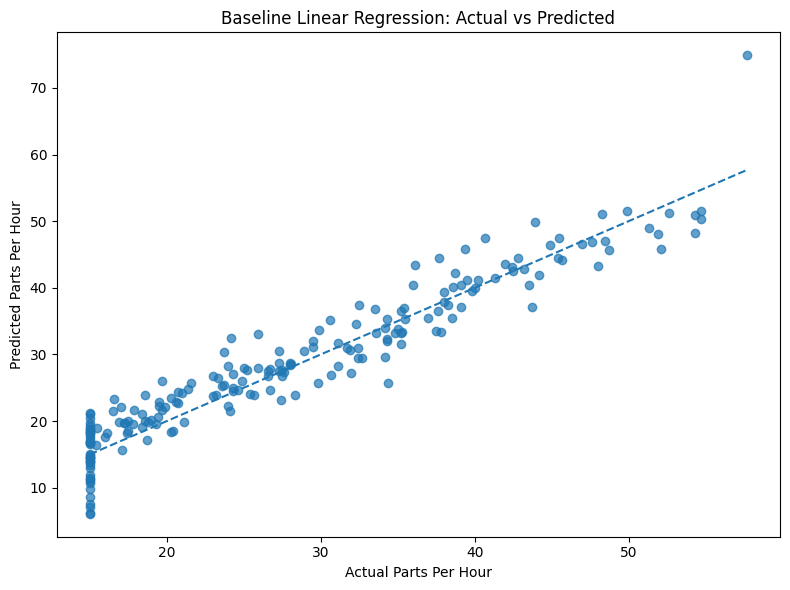

In [41]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    baseline_predictions,
    alpha=0.7
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.title("Baseline Linear Regression: Actual vs Predicted")
plt.xlabel("Actual Parts Per Hour")
plt.ylabel("Predicted Parts Per Hour")

plt.tight_layout()
plt.show()

## 20. Baseline Residual Analysis

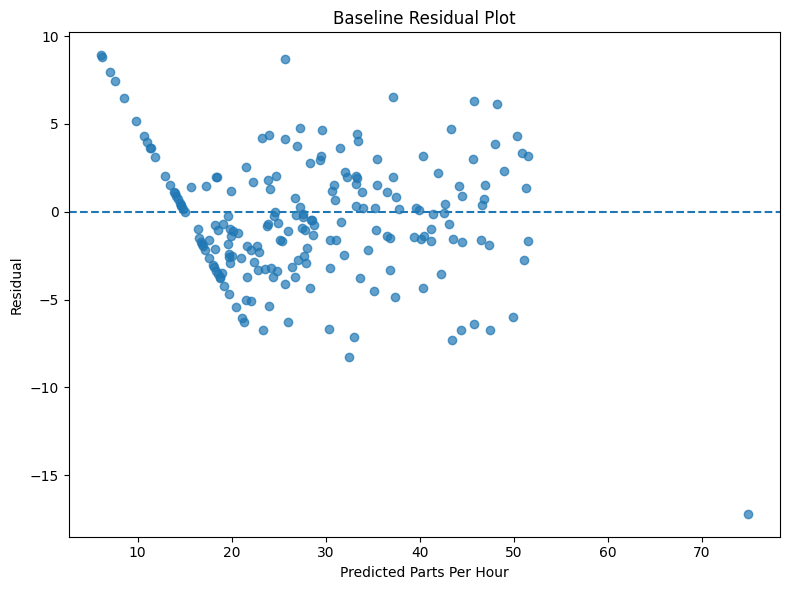

In [42]:
baseline_residuals = (
    y_test - baseline_predictions
)

plt.figure(figsize=(8, 6))

plt.scatter(
    baseline_predictions,
    baseline_residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title("Baseline Residual Plot")
plt.xlabel("Predicted Parts Per Hour")
plt.ylabel("Residual")

plt.tight_layout()
plt.show()

## 21. Multicollinearity Analysis using VIF

In [43]:
X_train_numeric = X_train[
    numerical_features
].copy()

X_train_numeric = X_train_numeric.fillna(
    X_train_numeric.median()
)

vif_rows = []

for i, feature in enumerate(
    X_train_numeric.columns
):
    vif_rows.append({
        "Feature": feature,
        "VIF": variance_inflation_factor(
            X_train_numeric.values,
            i
        )
    })

vif_data = pd.DataFrame(vif_rows)

vif_data = vif_data.sort_values(
    by="VIF",
    ascending=False
)

display(vif_data.round(2))

,Feature,VIF
6,Machine_Age,134.04
12,Machine_Utilization,133.82
11,Efficiency_Score,98.53
7,Operator_Experience,97.96
10,Total_Cycle_Time,45.17
2,Cycle_Time,42.05
9,Temperature_Pressure_Ratio,39.60
1,Injection_Pressure,32.35
0,Injection_Temperature,6.53
3,Cooling_Time,4.30


## 22. Refined Feature Set

The second team notebook used VIF/correlation analysis to reduce the feature set.

For the refined model, we retain the same feature-removal decision used in that notebook:

- `Machine_Age`
- `Efficiency_Score`
- `Total_Cycle_Time`
- `Temperature_Pressure_Ratio`

The remaining features are used for the final Linear Regression model.

In [44]:
features_to_remove = [
    "Machine_Age",
    "Efficiency_Score",
    "Total_Cycle_Time",
    "Temperature_Pressure_Ratio"
]

print("Features selected for removal:")
print(features_to_remove)

Features selected for removal:
['Machine_Age', 'Efficiency_Score', 'Total_Cycle_Time', 'Temperature_Pressure_Ratio']


In [45]:
X_train_reduced = X_train.drop(
    columns=features_to_remove
)

X_test_reduced = X_test.drop(
    columns=features_to_remove
)

print(
    "Original feature count:",
    X_train.shape[1]
)

print(
    "Reduced feature count:",
    X_train_reduced.shape[1]
)

Original feature count: 19
Reduced feature count: 15


In [46]:
print("Remaining features:")
print(X_train_reduced.columns.tolist())

Remaining features:
['Injection_Temperature', 'Injection_Pressure', 'Cycle_Time', 'Cooling_Time', 'Material_Viscosity', 'Ambient_Temperature', 'Operator_Experience', 'Maintenance_Hours', 'Shift', 'Machine_Type', 'Material_Grade', 'Day_of_Week', 'Machine_Utilization', 'Hour_Sin', 'Hour_Cos']


## 23. Identify Refined Feature Types

In [47]:
reduced_numerical_features = (
    X_train_reduced
    .select_dtypes(include=["int64", "float64"])
    .columns
    .tolist()
)

reduced_categorical_features = (
    X_train_reduced
    .select_dtypes(include=["object"])
    .columns
    .tolist()
)

print("Refined numerical features:")
print(reduced_numerical_features)

print("\nRefined categorical features:")
print(reduced_categorical_features)

Refined numerical features:
['Injection_Temperature', 'Injection_Pressure', 'Cycle_Time', 'Cooling_Time', 'Material_Viscosity', 'Ambient_Temperature', 'Operator_Experience', 'Maintenance_Hours', 'Machine_Utilization', 'Hour_Sin', 'Hour_Cos']

Refined categorical features:
['Shift', 'Machine_Type', 'Material_Grade', 'Day_of_Week']


## 24. Build Refined Preprocessing Pipeline

In [48]:
reduced_numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

reduced_categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

reduced_preprocessor = ColumnTransformer([
    (
        "numerical",
        reduced_numerical_pipeline,
        reduced_numerical_features
    ),
    (
        "categorical",
        reduced_categorical_pipeline,
        reduced_categorical_features
    )
])

print("Refined preprocessor created.")

Refined preprocessor created.


## 25. Build Refined Linear Regression Model

In [49]:
final_model = Pipeline([
    (
        "preprocessor",
        reduced_preprocessor
    ),
    (
        "model",
        LinearRegression()
    )
])

print("Final Linear Regression pipeline created.")

Final Linear Regression pipeline created.


## 26. Train Final Model

In [50]:
final_model.fit(
    X_train_reduced,
    y_train
)

print("Final model trained successfully.")

Final model trained successfully.


## 27. Generate Final Predictions

In [51]:
final_predictions = final_model.predict(
    X_test_reduced
)

print(
    "Final predictions generated:",
    len(final_predictions)
)

Final predictions generated: 200


## 28. Evaluate Final Model

In [52]:
final_mse = mean_squared_error(
    y_test,
    final_predictions
)

final_rmse = np.sqrt(
    final_mse
)

final_mae = mean_absolute_error(
    y_test,
    final_predictions
)

final_r2 = r2_score(
    y_test,
    final_predictions
)

In [53]:
final_results = pd.DataFrame({
    "Metric": [
        "MSE",
        "RMSE",
        "MAE",
        "R²"
    ],
    "Value": [
        final_mse,
        final_rmse,
        final_mae,
        final_r2
    ]
})

display(
    final_results.round(4)
)

,Metric,Value
0,MSE,12.4990
1,RMSE,3.5354
2,MAE,2.8119
3,R²,0.9042


## 29. Baseline vs Final Model

In [54]:
comparison = pd.DataFrame({
    "Model": [
        "Baseline Linear Regression",
        "Refined Linear Regression"
    ],
    "MSE": [
        baseline_mse,
        final_mse
    ],
    "RMSE": [
        baseline_rmse,
        final_rmse
    ],
    "MAE": [
        baseline_mae,
        final_mae
    ],
    "R²": [
        baseline_r2,
        final_r2
    ]
})

display(
    comparison.round(4)
)

,Model,MSE,RMSE,MAE,R²
0,Baseline Linear Regression,12.548,3.5423,2.7268,0.9038
1,Refined Linear Regression,12.499,3.5354,2.8119,0.9042


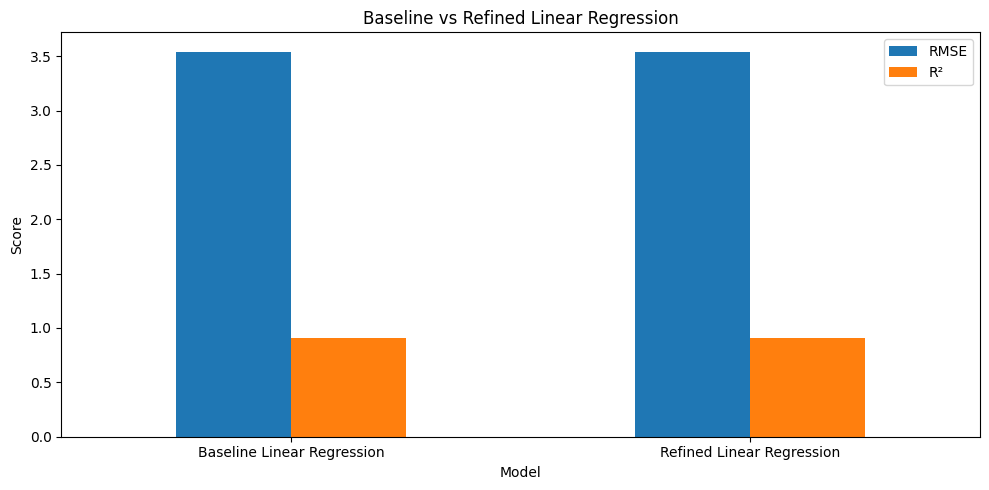

In [55]:
comparison.set_index("Model")[
    ["RMSE", "R²"]
].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Baseline vs Refined Linear Regression")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 30. Final Actual vs Predicted

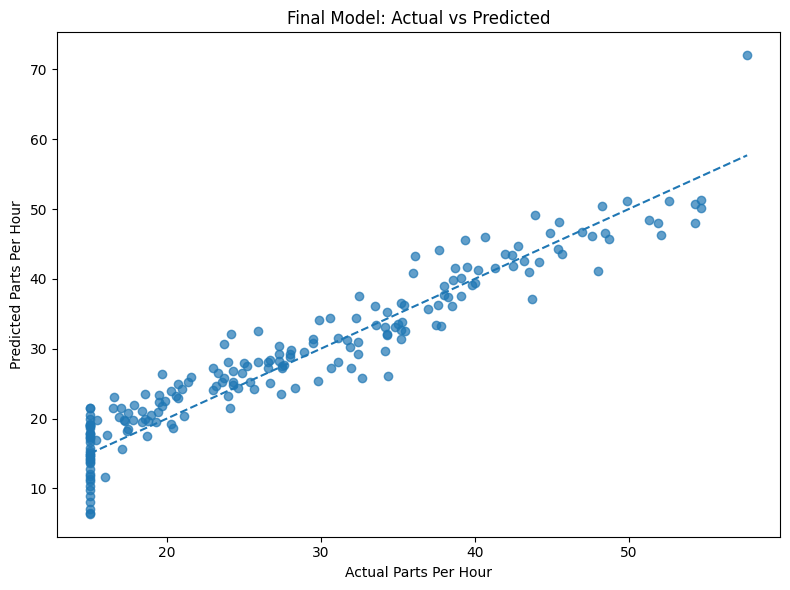

In [56]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    final_predictions,
    alpha=0.7
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.title("Final Model: Actual vs Predicted")
plt.xlabel("Actual Parts Per Hour")
plt.ylabel("Predicted Parts Per Hour")

plt.tight_layout()
plt.show()

## 31. Final Residual Analysis

In [57]:
final_residuals = (
    y_test - final_predictions
)

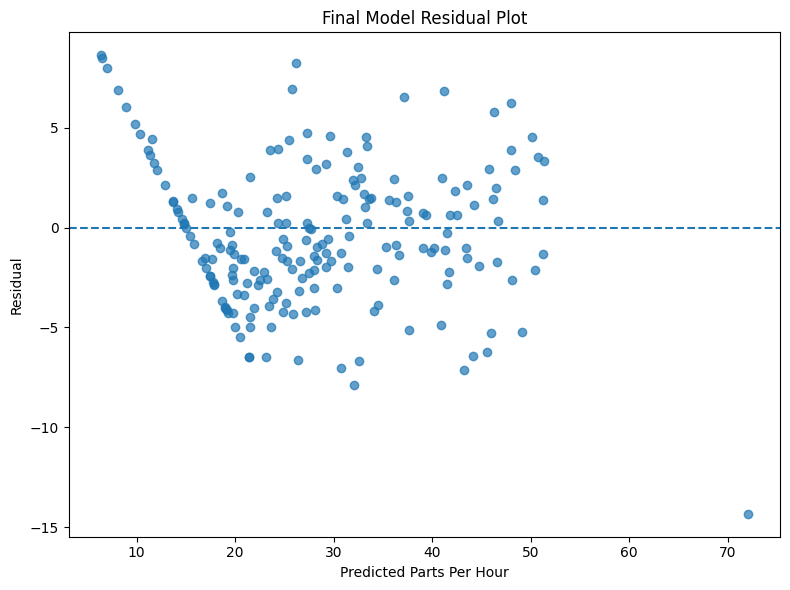

In [58]:
plt.figure(figsize=(8, 6))

plt.scatter(
    final_predictions,
    final_residuals,
    alpha=0.7
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title("Final Model Residual Plot")
plt.xlabel("Predicted Parts Per Hour")
plt.ylabel("Residual")

plt.tight_layout()
plt.show()

## 32. Prediction Error Analysis

In [59]:
error_analysis = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": final_predictions,
    "Absolute_Error": np.abs(
        y_test.values - final_predictions
    )
})

error_analysis = error_analysis.sort_values(
    by="Absolute_Error",
    ascending=False
)

display(
    error_analysis.head(10).round(3)
)

,Actual,Predicted,Absolute_Error
86,57.7,72.029,14.329
73,15.0,6.372,8.628
106,15.0,6.486,8.514
11,34.4,26.147,8.253
105,15.0,7.001,7.999
9,24.2,32.100,7.900
22,36.1,43.242,7.142
149,23.7,30.753,7.053
186,32.7,25.780,6.920
116,15.0,8.130,6.870


## 33. Linear Regression Coefficient Analysis

In [60]:
feature_names = (
    final_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

coefficients = (
    final_model
    .named_steps["model"]
    .coef_
)

coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coefficient_df["Absolute_Coefficient"] = (
    coefficient_df["Coefficient"].abs()
)

coefficient_df = coefficient_df.sort_values(
    by="Absolute_Coefficient",
    ascending=False
)

display(
    coefficient_df.head(15).round(4)
)

,Feature,Coefficient,Absolute_Coefficient
2,numerical__Cycle_Time,-10.1238,10.1238
6,numerical__Operator_Experience,3.8309,3.8309
14,categorical__Machine_Type_Type_A,2.1381,2.1381
13,categorical__Shift_Night,-2.1263,2.1263
0,numerical__Injection_Temperature,2.0210,2.0210
11,categorical__Shift_Day,2.0068,2.0068
1,numerical__Injection_Pressure,1.9562,1.9562
16,categorical__Machine_Type_Type_C,-1.8384,1.8384
8,numerical__Machine_Utilization,1.7522,1.7522
17,categorical__Material_Grade_Economy,-1.6070,1.6070


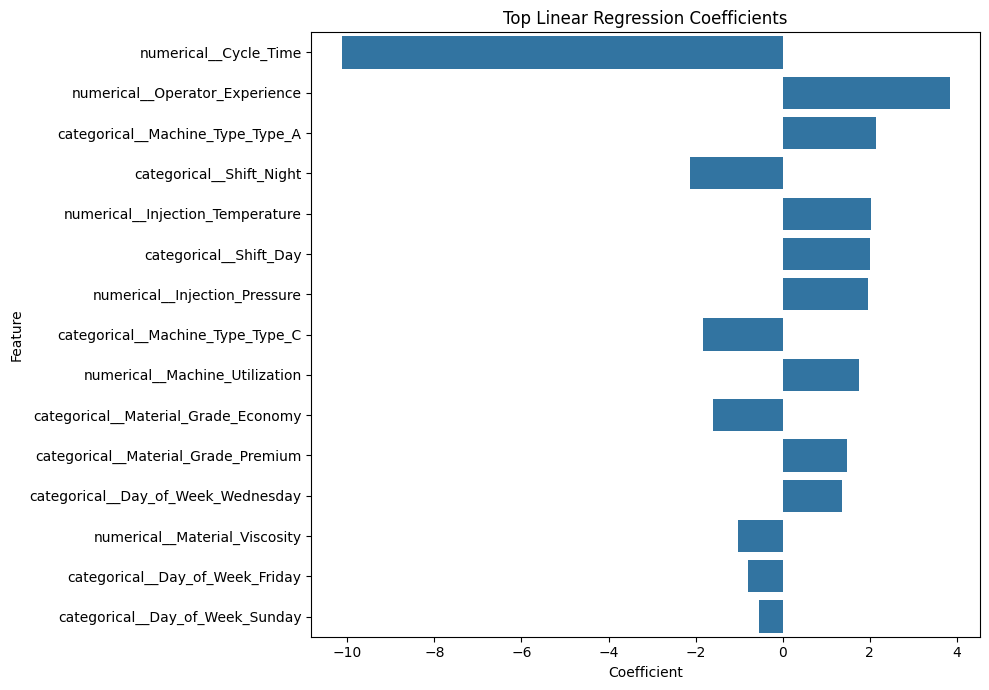

In [61]:
top_coefficients = coefficient_df.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_coefficients,
    x="Coefficient",
    y="Feature"
)

plt.title("Top Linear Regression Coefficients")
plt.tight_layout()
plt.show()

## 34. Prepare Model Output Folder

In [62]:
MODEL_DIR = "models"

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

print("Model directory ready:", MODEL_DIR)

Model directory ready: models


## 35. Save Final Model Pipeline

In [63]:
MODEL_PATH = os.path.join(
    MODEL_DIR,
    "manufacturing_output_prediction_model.pkl"
)

joblib.dump(
    final_model,
    MODEL_PATH
)

print("Final model saved to:")
print(MODEL_PATH)

Final model saved to:
models\manufacturing_output_prediction_model.pkl


## 36. Save Model Metrics

In [64]:
METRICS_PATH = os.path.join(
    MODEL_DIR,
    "model_metrics.csv"
)

comparison.to_csv(
    METRICS_PATH,
    index=False
)

print("Model metrics saved to:")
print(METRICS_PATH)

Model metrics saved to:
models\model_metrics.csv


## 37. Save Final Feature Configuration

In [65]:
FEATURE_CONFIG = {
    "target": TARGET,
    "features_used": X_train_reduced.columns.tolist(),
    "features_removed": features_to_remove,
    "categorical_features": reduced_categorical_features,
    "numerical_features": reduced_numerical_features,
    "timestamp_features": [
        "Hour_Sin",
        "Hour_Cos"
    ]
}

CONFIG_PATH = os.path.join(
    MODEL_DIR,
    "feature_config.json"
)

with open(
    CONFIG_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        FEATURE_CONFIG,
        file,
        indent=4
    )

print("Feature configuration saved to:")
print(CONFIG_PATH)

Feature configuration saved to:
models\feature_config.json


## 38. Verify the Saved Model

In [66]:
loaded_model = joblib.load(
    MODEL_PATH
)

loaded_predictions = loaded_model.predict(
    X_test_reduced
)

print("Saved model loaded successfully.")
print(
    "Predictions identical:",
    np.allclose(
        final_predictions,
        loaded_predictions
    )
)

Saved model loaded successfully.
Predictions identical: True


## 39. Test a Single Prediction

In [67]:
sample_input = X_test_reduced.iloc[[0]].copy()

sample_prediction = loaded_model.predict(
    sample_input
)[0]

print(
    f"Actual Parts Per Hour: "
    f"{y_test.iloc[0]:.2f}"
)

print(
    f"Predicted Parts Per Hour: "
    f"{sample_prediction:.2f}"
)

Actual Parts Per Hour: 18.60
Predicted Parts Per Hour: 19.92


## 40. Final Model Summary

The final deployment model is a **Linear Regression pipeline** containing:

- Median imputation for missing numerical values
- Most-frequent imputation for categorical values
- StandardScaler for numerical features
- One-hot encoding for categorical features
- Cyclic hour features (`Hour_Sin`, `Hour_Cos`)
- Refined feature set based on the team notebook's feature-reduction step

The saved `.pkl` pipeline will be used later by the **Streamlit application**.

### Deployment file
`models/manufacturing_output_prediction_model.pkl`

The Streamlit UI should load this complete pipeline rather than rebuilding preprocessing separately.